In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

print("Everything is working!")
print(sp.__version__)

Everything is working!
1.14.0


# Quantitative Methods I – Part 3
## Task 1: Mathematical Analysis

In this assignment, I will study the function:

\[
f(x)=x^2+2\ln(x)+2
\]

I will use Python to calculate derivatives, find roots, create graphs and calculate integrals.

In [ ]:
def f(x):
    return x**2 + 2*np.log(x) + 2

In [ ]:
x = 1

result = f(x)

print("When x =", x)
print("f(x) =", result)

When x = 1
f(x) = 3.0


## 1. Domain

The function contains the natural logarithm ln(x). The logarithm is only defined for positive real numbers.

Therefore, the mathematical domain is x > 0.

For this assignment, I choose the interval [0.1, 3] for numerical calculations and plotting. This interval avoids zero and negative values and allows me to study the behaviour of the function.

In [ ]:
x_values = np.linspace(0.1, 3, 500)

plt.figure(figsize=(8, 5))

plt.plot(x_values, f(x_values))

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Graph of f(x) = x² + 2ln(x) + 2")

plt.grid(True)
plt.show()

## 2. First Derivative

The first derivative describes the rate of change of the function.

Using the power rule and logarithmic differentiation rules:

- The derivative of x² is 2x.
- The derivative of 2ln(x) is 2/x.
- The derivative of the constant 2 is 0.

Therefore:

f'(x) = 2x + 2/x

In [ ]:
def f_prime(x):
  return 2*x + 2/x

print("First derivative at x = 1:", f_prime(1))

### Second Derivative

The second derivative describes how the first derivative changes.

Starting with:

f'(x) = 2x + 2/x

Differentiating again gives:

f''(x) = 2 - 2/x²

The second derivative helps us understand the curvature of the function.

In [ ]:
def f_double_prime(x):
  return 2 - 2/x**2

print("Second derivative at x = 1:", f_double_prime(1))

## 3. Symbolic Differentiation Using SymPy

SymPy is a Python library used for symbolic mathematics. It can calculate derivatives automatically.

I will use SymPy to calculate the first and second derivatives and compare them with my manual calculations.

In [ ]:
# Define the symbolic variable
x = sp.symbols('x', positive=True)

#Define the mathematical function
f_sym = x**2 + 2*sp.log(x) + 2

#calculate first derivative
first_derivative = sp.diff(f_sym, x)

#calculate second derivative
second_derivative = sp.diff(first_derivative, x)

print("original function:", f_sym)
print("first derivative:", first_derivative)
print("second derivative:", second_derivative)

## 4. Numerical Differentiation Using Central Difference

The central difference method estimates the derivative by using two points close to the selected value of x.

I use h = 0.00001 and compare the numerical derivative with the analytical derivative at three different points.

In [ ]:
# Define the central difference menthod
def numerical_derivative(x_value, h=1e-5):
  return (f(x_value + h) - f(x_value - h)) / (2 * h)


  #select three test points
  test_points = [0.5, 1.0, 2.0]


  # compare analtical and numerical derivatives
  for point in test_points:
    analytical = f_prime(point)
    numerical = numerical_derivative(point)
    difference = abs(analytical - numerical)

    print("At x =", point)
    print("Analytical derivatives:", analytical)
    print("numerical derivative:", numerical)
    print("difference:", difference)
    print("--------")


In [ ]:
# Define the central difference method
def numerical_derivative(x_value, h=1e-5):
    return (f(x_value + h) - f(x_value - h)) / (2 * h)

# Select three test points
test_points = [0.5, 1.0, 2.0]

# Compare analytical and numerical derivatives
for point in test_points:
    analytical = f_prime(point)
    numerical = numerical_derivative(point)
    difference = abs(analytical - numerical)

    print("At x =", point)
    print("Analytical derivative:", analytical)
    print("Numerical derivative:", numerical)
    print("Difference:", difference)
    print("--------------------------")

At x = 0.5
Analytical derivative: 5.0
Numerical derivative: 5.000000000521254
Difference: 5.212541509536095e-10
--------------------------
At x = 1.0
Analytical derivative: 4.0
Numerical derivative: 4.000000000070614
Difference: 7.061373707983876e-11
--------------------------
At x = 2.0
Analytical derivative: 5.0
Numerical derivative: 5.000000000032756
Difference: 3.275602011854062e-11
--------------------------


### Result and Interpretation

The numerical derivatives are very close to the analytical derivatives at all three test points.

The differences are extremely small, which shows that the central difference method provides an accurate approximation of the first derivative when a small step size is used.

## 5. Tangent Line

A tangent line touches the function at a specific point. Its slope is equal to the first derivative at that point.

I calculate the tangent line at x0 = 1. The function value is 3 and the slope is 4.

Therefore, the tangent line is y = 4x - 1.

In [ ]:
# Define the tangent point
x0 = 1

# Calculate the function value and slope
y0 = f(x0)
slope = f_prime(x0)

# Define the tangent line
def tangent_line(x_value):
    return slope * (x_value - x0) + y0

print("Point of contact:", (x0, y0))
print("Slope:", slope)
print("Tangent line: y =", slope, "x - 1")

Point of contact: (1, np.float64(3.0))
Slope: 4.0
Tangent line: y = 4.0 x - 1


### Plot of the Function and Tangent Line

The graph below shows the original function and its tangent line at x = 1.

The tangent line touches the function at the point (1, 3), and its slope is 4.

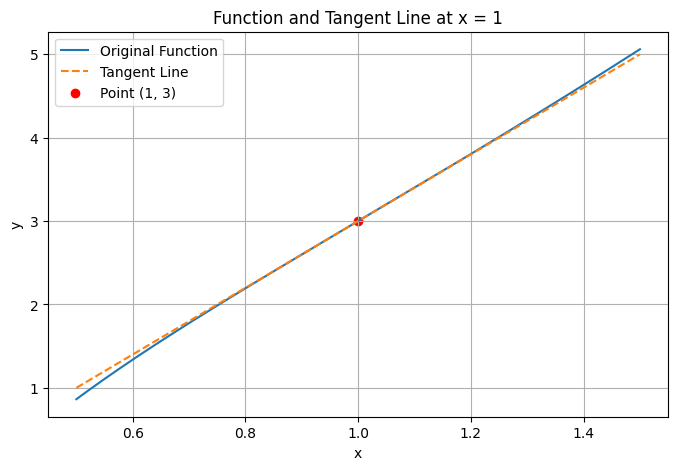

In [ ]:
# Create x values for the graph
x_values = np.linspace(0.5, 1.5, 500)

# Calculate function and tangent line values
function_values = f(x_values)
tangent_values = tangent_line(x_values)

# Plot both lines
plt.figure(figsize=(8, 5))
plt.plot(x_values, function_values, label="Original Function")
plt.plot(x_values, tangent_values, label="Tangent Line", linestyle="--")

# Mark the point of contact
plt.scatter(x0, y0, color="red", label="Point (1, 3)")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Function and Tangent Line at x = 1")
plt.legend()
plt.grid(True)
plt.show()

## 6. Finding the Root Using Newton's Method

Newton's method is a numerical method used to find the root of a function.

The aim is to find a value of x where f(x) is approximately zero.

I use an initial guess of 0.2, a tolerance of 0.000001 and a maximum of 50 iterations.

In [ ]:
# Define Newton's method
def newton_method(x0, tol=1e-6, max_iter=50):

    x_current = x0

    for i in range(1, max_iter + 1):

        fx = f(x_current)
        dfx = f_prime(x_current)

        x_next = x_current - fx / dfx

        print("Iteration:", i)
        print("Current x:", x_current)
        print("Next x:", x_next)
        print("Function value:", f(x_next))
        print("----------------------")

        if abs(x_next - x_current) < tol:
            print("Convergence achieved!")
            return x_next

        x_current = x_next

    print("Maximum iterations reached.")
    return x_current


# Run Newton's method
root = newton_method(0.2)

print("Approximate root:", root)
print("Function value at root:", f(root))

Iteration: 1
Current x: 0.2
Next x: 0.31335344469886545
Function value: -0.22265663716902395
----------------------
Iteration: 2
Current x: 0.31335344469886545
Next x: 0.3451194414830899
Function value: -0.008622000448997191
----------------------
Iteration: 3
Current x: 0.3451194414830899
Next x: 0.34644890275848206
Function value: -1.3033803368145414e-05
----------------------
Iteration: 4
Current x: 0.34644890275848206
Next x: 0.34645091857931126
Function value: -2.979172464279145e-11
----------------------
Iteration: 5
Current x: 0.34645091857931126
Next x: 0.3464509185839189
Function value: 0.0
----------------------
Convergence achieved!
Approximate root: 0.3464509185839189
Function value at root: 0.0


### Result and Interpretation

Newton's method successfully found the approximate root of the function.

The calculated root is approximately 0.3464509186. The method converged after 5 iterations using an initial guess of 0.2.

The function value at the calculated root is approximately zero. This shows that Newton's method successfully found the root within the required tolerance.

## 7. Fourth-Order Taylor Approximation

A Taylor polynomial approximates a function near a selected point.

I use a fourth-order Taylor polynomial around the root found using Newton's method.

I will compare the original function and its Taylor approximation using a graph.

In [ ]:
# Calculate the fourth-order Taylor polynomial
taylor_polynomial = sp.series(
    f_sym, x, root, 5
).removeO()

# Display the Taylor polynomial
print("Fourth-order Taylor polynomial:")
sp.pprint(taylor_polynomial)

Fourth-order Taylor polynomial:
 2               
x  + 2⋅log(x) + 2


In [ ]:
# Convert the Newton root into a SymPy number
root_sym = sp.Float(root, 15)

# Calculate the fourth-order Taylor polynomial
taylor_polynomial = sp.series(
    f_sym, x, root_sym, 5
).removeO()

# Display the result
print("Root:", root_sym)
print("Fourth-order Taylor polynomial:")
sp.pprint(taylor_polynomial)

Root: 0.346450918583919
Fourth-order Taylor polynomial:
 2               
x  + 2⋅log(x) + 2


In [ ]:
# Create a fresh symbolic variable
x_symbol = sp.symbols('x', positive=True)

# Define the original function symbolically
f_symbolic = x_symbol**2 + 2*sp.log(x_symbol) + 2

# Convert the numerical root into a SymPy number
root_sym = sp.Float(root, 15)

# Start the Taylor polynomial
taylor_polynomial = 0

# Calculate the Taylor polynomial up to order 4
for k in range(5):

    derivative_k = sp.diff(f_symbolic, x_symbol, k)

    coefficient = derivative_k.subs(
        x_symbol, root_sym
    ) / sp.factorial(k)

    taylor_polynomial += coefficient * (x_symbol - root_sym)**k

# Simplify the result
taylor_polynomial = sp.expand(taylor_polynomial)

# Display the polynomial
print("Root:", root_sym)
print("Fourth-order Taylor polynomial:")
sp.pprint(taylor_polynomial)

Root: 0.346450918583919
Fourth-order Taylor polynomial:
                    4                     3                     2              ↪
- 34.7058859821976⋅x  + 64.1273924202725⋅x  - 48.9882365233884⋅x  + 23.0912939 ↪

↪                            
↪ 492242⋅x - 4.28669490565431


### Comparison of Original Function and Taylor Approximation

I plot the original function and its fourth-order Taylor polynomial on the same graph.

The graph helps me understand how accurately the Taylor polynomial approximates the original function near the calculated root.

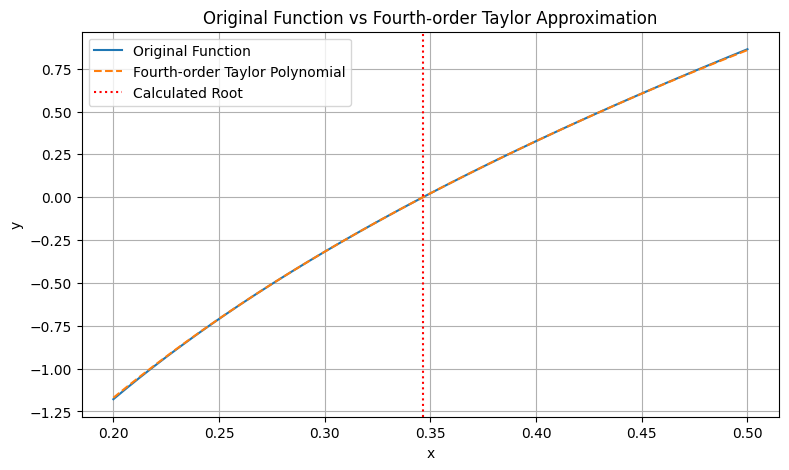

In [ ]:
# Convert the Taylor polynomial into a numerical function
taylor_function = sp.lambdify(x_symbol, taylor_polynomial, "numpy")

# Select values around the root
x_values = np.linspace(0.2, 0.5, 500)

# Calculate both functions
original_values = f(x_values)
taylor_values = taylor_function(x_values)

# Plot the comparison
plt.figure(figsize=(9, 5))

plt.plot(x_values, original_values, label="Original Function")
plt.plot(x_values, taylor_values, "--", label="Fourth-order Taylor Polynomial")

plt.axvline(root, color="red", linestyle=":", label="Calculated Root")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Original Function vs Fourth-order Taylor Approximation")
plt.legend()
plt.grid(True)
plt.show()

### Result and Interpretation

The graph shows that the fourth-order Taylor polynomial closely follows the original function near the calculated root.

The approximation is more accurate near the expansion point. As the distance from the root increases, the difference between the original function and the Taylor polynomial may become larger.

## 8. Numerical Integration

Integration is used to calculate the area under a function over a specified interval.

I calculate the definite integral of the original function from 0.5 to 1.5.

I use the trapezoidal rule with 1000 subdivisions and compare the result with analytical and symbolic integration.

In [ ]:
# Define the integration interval
a = 0.5
b = 1.5

# Number of subdivisions
n = 1000

# Create equally spaced x values
x_points = np.linspace(a, b, n + 1)

# Calculate function values
y_points = f(x_points)

# Calculate the integral using the trapezoidal rule
trapezoidal_result = np.trapezoid(y_points, x_points)

print("Integration interval:", a, "to", b)
print("Number of subdivisions:", n)
print("Trapezoidal integration result:", trapezoidal_result)

Integration interval: 0.5 to 1.5
Number of subdivisions: 1000
Trapezoidal integration result: 2.992875782662259


## 9. Analytical Integration

I calculate the definite integral using the analytical antiderivative of the original function.

The antiderivative is F(x) = x³/3 + 2x ln(x).

I evaluate it at the upper and lower integration limits and subtract the results.

In [ ]:
# Define the antiderivative
def F(x):
    return (x**3 / 3) + (2 * x * np.log(x))

# Calculate the definite integral
analytical_result = F(b) - F(a)

print("Analytical integration result:", analytical_result)

Analytical integration result: 2.9928758382177714


In [ ]:
# Calculate the definite integral using SymPy
sympy_integral = sp.integrate(f_symbolic, (x_symbol, a, b))

# Convert the result to a numerical value
sympy_result = float(sympy_integral)

print("SymPy integration result:", sympy_result)

SymPy integration result: 2.9928758382177714


In [ ]:
# Calculate absolute errors
error_trapezoidal = abs(trapezoidal_result - analytical_result)
error_sympy = abs(sympy_result - analytical_result)

print("Trapezoidal absolute error:", error_trapezoidal)
print("SymPy absolute error:", error_sympy)

Trapezoidal absolute error: 5.555551219060817e-08
SymPy absolute error: 0.0


In [ ]:
import pandas as pd

comparison = pd.DataFrame({
    "Method": ["Trapezoidal Rule", "Analytical Integration", "SymPy Integration"],
    "Integral Result": [
        trapezoidal_result,
        analytical_result,
        sympy_result
    ],
    "Absolute Error": [
        error_trapezoidal,
        0.0,
        error_sympy
    ]
})

display(comparison)

,Method,Integral Result,Absolute Error
0,Trapezoidal Rule,2.992876,5.555551e-08
1,Analytical Integration,2.992876,0.000000e+00
2,SymPy Integration,2.992876,0.000000e+00


### Conclusion – Numerical Integration

I calculated the definite integral of the function over the interval [0.5, 1.5] using three different methods.

The trapezoidal rule with 1,000 subdivisions gave a result of approximately 2.9928757827. Analytical integration and SymPy both gave approximately 2.9928758382.

The absolute error of the trapezoidal method was approximately 0.0000000556, while the SymPy result matched the analytical result exactly.

This comparison shows that the trapezoidal rule provides a very accurate numerical approximation when a sufficiently large number of subdivisions is used.